# Fairness over the course of a module (OULAD)

**Question:** as the course goes on and the model sees more of each student's record, how do its fairness gaps change, and why?

**Design**
- **Same students throughout.** Students who finished the module (Pass, Distinction or Fail). They are split once, by student, into a training group (70%) and a test group (30%), and the split never changes.
- **Ten snapshots** at 10%, 20%, ... 100% of each course's length. At each snapshot the model is retrained on the same training students using only their records up to that point, and tested on the same test students.
- **Target:** Fail vs Pass/Distinction. Each student's label never changes, so any change in fairness comes from what the model knows, not from who is in the data.
- **Uncertainty:** 1,000 bootstrap resamples of the test students (same students, drawn with replacement).
- **Fairness metrics** (gap = group minus comparison group, in percentage points): flag rate (demographic parity), false-alarm rate among students who passed (predictive equality), hit rate among students who failed (equal opportunity).

Data: [Open University Learning Analytics Dataset](https://analyse.kmi.open.ac.uk/open_dataset) (Kuzilek et al., 2017), CC BY 4.0. Click data aggregated to daily totals per student from the authors' [R package](https://github.com/jakubkuzilek/oulad).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED     = 42
PCTS     = list(range(10, 101, 10))   # snapshots: % of course length
WEEKS    = list(range(3, 34, 3))      # calendar-week check (all runs last at least 33 weeks)
N_BOOT   = 1000
FOCUS    = "deprived"                 # attribute used for the detailed plots

DATA_URL = "https://raw.githubusercontent.com/DEHO-OSCAR-BLESSED/fairness-in-learning-analytics-demo/main/data"
DATA = "data" if os.path.isdir("data") else DATA_URL
COLORS = {"flag": "#2a78d6", "fpr": "#eb6834", "tpr": "#1baf7a"}
NAMES  = {"flag": "Flag rate", "fpr": "False alarms", "tpr": "Hit rate"}

## 1. Load the data and define the cohort

In [2]:
K = ["code_module", "code_presentation", "id_student"]
CR = ["code_module", "code_presentation"]
info    = pd.read_csv(f"{DATA}/studentInfo.csv")
reg     = pd.read_csv(f"{DATA}/studentRegistration.csv", na_values="?")
assess  = pd.read_csv(f"{DATA}/assessments.csv", na_values="?")
sa      = pd.read_csv(f"{DATA}/studentAssessment.csv", na_values="?")
courses = pd.read_csv(f"{DATA}/courses.csv")
vle     = pd.read_csv(f"{DATA}/vle_daily.csv.gz")

# Cohort: students who finished the module
df = info[info.final_result != "Withdrawn"].copy()
df = df.merge(reg[K + ["date_registration"]], on=K, how="left").merge(courses, on=CR)
df["date_registration"] = df.date_registration.fillna(df.date_registration.median())
df["y"] = (df.final_result == "Fail").astype(int)
df["imd_band"] = df.imd_band.replace({"10-20": "10-20%"}).fillna("Unknown")
df = df.reset_index(drop=True)

# Groups audited (1 = group of interest). Students with unknown IMD are left out of the IMD audit only.
ATTRS = {
    "deprived":    ("IMD 0-30% (most deprived)", "IMD 40-100%"),
    "female":      ("Female", "Male"),
    "disabled":    ("Declared disability", "No disability"),
    "age35":       ("Aged 35+", "Under 35"),
    "non_england": ("Scotland, Wales, Ireland", "England"),
    "low_edu":     ("Below A-level", "A-level or higher"),
}
df["deprived"]    = np.where(df.imd_band == "Unknown", np.nan, df.imd_band.isin(["0-10%", "10-20%", "20-30%"]).astype(float))
df["female"]      = (df.gender == "F").astype(float)
df["disabled"]    = (df.disability == "Y").astype(float)
df["age35"]       = (df.age_band != "0-35").astype(float)
df["non_england"] = df.region.isin(["Scotland", "Wales", "Ireland"]).astype(float)
df["low_edu"]     = df.highest_education.isin(["No Formal quals", "Lower Than A Level"]).astype(float)

print(f"{len(df):,} enrolments | fail rate {df.y.mean():.1%}")
pd.DataFrame({a: {"group share": f"{df[a].mean():.1%}",
                  "fail rate (group)": f"{df.y[df[a] == 1].mean():.1%}",
                  "fail rate (comparison)": f"{df.y[df[a] == 0].mean():.1%}"} for a in ATTRS}).T

22,437 enrolments | fail rate 31.4%


,group share,fail rate (group),fail rate (comparison)
deprived,31.0%,40.0%,28.5%
female,45.6%,30.3%,32.4%
disabled,8.6%,37.1%,30.9%
age35,30.6%,26.5%,33.6%
non_england,22.3%,34.6%,30.5%
low_edu,38.9%,40.3%,25.8%


## 2. Features at a snapshot

At a cut-off day, the model sees only what happened by then:
- **Fixed:** module, gender, region, prior education, IMD band, age band, disability, previous attempts, credits, registration date.
- **Clicks:** total clicks, active days, clicks in the last 14 days (clicks before the course start count).
- **Assessments:** for coursework due by the cut-off and submitted by then: mean score, submission rate, number due, number submitted late.

In [3]:
FIXED_CAT = ["code_module", "gender", "region", "highest_education", "imd_band", "age_band", "disability"]
FIXED_NUM = ["num_of_prev_attempts", "studied_credits", "date_registration"]
CLICKS    = ["log_clicks", "active_days", "log_clicks_14d"]
ASSESS    = ["mean_score", "submit_rate", "n_due", "n_late"]
BEHAV     = CLICKS + ASSESS
coursework = assess[assess.assessment_type != "Exam"]
sa_cw = sa.merge(coursework[["id_assessment"] + CR + ["date"]], on="id_assessment")

def features(cut):
    """cut: Series of cut-off days, aligned with df rows."""
    X = df.copy()
    X["cut"] = cut.values
    cuts = X[K + ["cut"]]
    v = vle.merge(cuts, on=K)
    v = v[v.date <= v.cut]
    agg = v.groupby(K).agg(clicks=("sum_click", "sum"), active_days=("date", "nunique")).reset_index()
    last = v[v.date > v.cut - 14].groupby(K).sum_click.sum().rename("clicks_14d").reset_index()
    s = sa_cw.merge(cuts, on=K)
    s = s[(s.date <= s.cut) & (s.date_submitted <= s.cut)]
    s = s.assign(late=(s.date_submitted > s.date).astype(int))
    s_agg = s.groupby(K).agg(mean_score=("score", "mean"), n_sub=("score", "size"), n_late=("late", "sum")).reset_index()
    due = coursework.merge(X[CR + ["cut"]].drop_duplicates(), on=CR)
    n_due = due[due.date <= due.cut].groupby(CR + ["cut"]).size().rename("n_due").reset_index()
    X = X.merge(agg, on=K, how="left").merge(last, on=K, how="left").merge(s_agg, on=K, how="left")
    X = X.merge(n_due, on=CR + ["cut"], how="left")
    X[["clicks", "active_days", "clicks_14d", "mean_score", "n_sub", "n_late", "n_due"]] = \
        X[["clicks", "active_days", "clicks_14d", "mean_score", "n_sub", "n_late", "n_due"]].fillna(0)
    X["submit_rate"] = np.where(X.n_due > 0, X.n_sub / X.n_due.clip(lower=1), 0)
    X["log_clicks"], X["log_clicks_14d"] = np.log1p(X.clicks), np.log1p(X.clicks_14d)
    return X

def cut_pct(p):  return (df.module_presentation_length * p / 100).round()
def cut_week(w): return pd.Series(7 * w, index=df.index)

SNAP = {p: features(cut_pct(p)) for p in PCTS}
SNAP_W = {w: features(cut_week(w)) for w in WEEKS}
SNAP[30][CLICKS + ASSESS].describe().round(2)

,log_clicks,active_days,log_clicks_14d,mean_score,submit_rate,n_due,n_late
count,22437.00,22437.00,22437.00,22437.00,22437.00,22437.00,22437.00
mean,5.80,30.32,2.57,70.99,0.89,2.32,0.58
std,1.52,21.21,1.98,23.96,0.27,0.70,0.81
min,0.00,0.00,0.00,0.00,0.00,1.00,0.00
25%,5.19,13.00,0.00,65.00,1.00,2.00,0.00
50%,6.06,26.00,2.83,78.00,1.00,2.00,0.00
75%,6.79,44.00,4.20,86.25,1.00,3.00,1.00
max,9.43,106.00,7.43,100.00,1.00,4.00,4.00


## 3. One fixed split, one model per snapshot

In [4]:
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=SEED).split(df, groups=df.id_student))
print(f"train {len(tr):,} | test {len(te):,} | test fail rate {df.y.iloc[te].mean():.1%}")

def make_model(cat, num):
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat), ("num", StandardScaler(), num)])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=3000))])

FEATSETS = {"full": (FIXED_CAT, FIXED_NUM + BEHAV), "fixed only": (FIXED_CAT, FIXED_NUM), "behaviour only": ([], BEHAV)}

def fit_snapshot(X):
    out = {}
    for name, (cat, num) in FEATSETS.items():
        m = make_model(cat, num).fit(X.iloc[tr], X.y.iloc[tr])
        s = m.predict_proba(X.iloc[te])[:, 1]
        out[name] = dict(model=m, score=s, pred=(s >= 0.5).astype(int))
    return out

FITS   = {p: fit_snapshot(SNAP[p]) for p in PCTS}
FITS_W = {w: fit_snapshot(SNAP_W[w]) for w in WEEKS}
y_te = df.y.values[te]
pd.DataFrame({p: {"AUC": roc_auc_score(y_te, FITS[p]["full"]["score"]),
                  "accuracy": (FITS[p]["full"]["pred"] == y_te).mean(),
                  "flagged": FITS[p]["full"]["pred"].mean()} for p in PCTS}).round(3)

train 15,679 | test 6,758 | test fail rate 31.6%


,10,20,30,40,50,60,70,80,90,100
AUC,0.777,0.823,0.855,0.882,0.904,0.920,0.932,0.942,0.951,0.949
accuracy,0.756,0.789,0.814,0.838,0.854,0.869,0.882,0.896,0.902,0.901
flagged,0.194,0.210,0.211,0.228,0.252,0.259,0.269,0.272,0.278,0.270


## 4. Fairness gaps with bootstrap intervals

In [5]:
rng = np.random.default_rng(SEED)
BOOT = rng.integers(0, len(te), size=(N_BOOT, len(te)))   # same resamples at every snapshot (paired)

def rates(pred, y, g):
    """pred, y, g: arrays (..., n); returns flag, fpr, tpr for g==1 minus g==0, in points."""
    res = {}
    for k, mask in {"flag": np.ones_like(y, bool), "fpr": y == 0, "tpr": y == 1}.items():
        r = []
        for grp in (1, 0):
            m = mask & (g == grp)
            r.append((pred * m).sum(-1) / np.maximum(m.sum(-1), 1))
        res[k] = 100 * (r[0] - r[1])
    return res

def gap_table(fits, points, model="full"):
    rows = []
    for a in ATTRS:
        g_all = df[a].values[te]
        for t in points:
            pred = fits[t][model]["pred"]
            ok = ~np.isnan(g_all)
            point = rates(pred[ok], y_te[ok], g_all[ok])
            P, Y, G = pred[BOOT], y_te[BOOT], g_all[BOOT]
            V = ~np.isnan(G)
            boot = rates(P * V, Y, np.where(V, G, -1))
            for k in NAMES:
                lo, hi = np.percentile(boot[k], [2.5, 97.5])
                rows.append(dict(attr=a, t=t, metric=k, gap=point[k], lo=lo, hi=hi))
    return pd.DataFrame(rows)

GAPS = gap_table(FITS, PCTS)
GAPS[GAPS.attr == FOCUS].pivot(index="t", columns="metric", values="gap").round(1)

metric,flag,fpr,tpr
t,,,
10,16.0,7.9,20.0
20,16.6,8.0,18.4
30,14.2,4.2,16.5
40,12.8,3.7,11.2
50,11.8,2.9,7.7
60,11.5,1.5,8.2
70,12.1,1.8,8.0
80,12.3,2.4,6.5
90,12.3,2.0,6.5


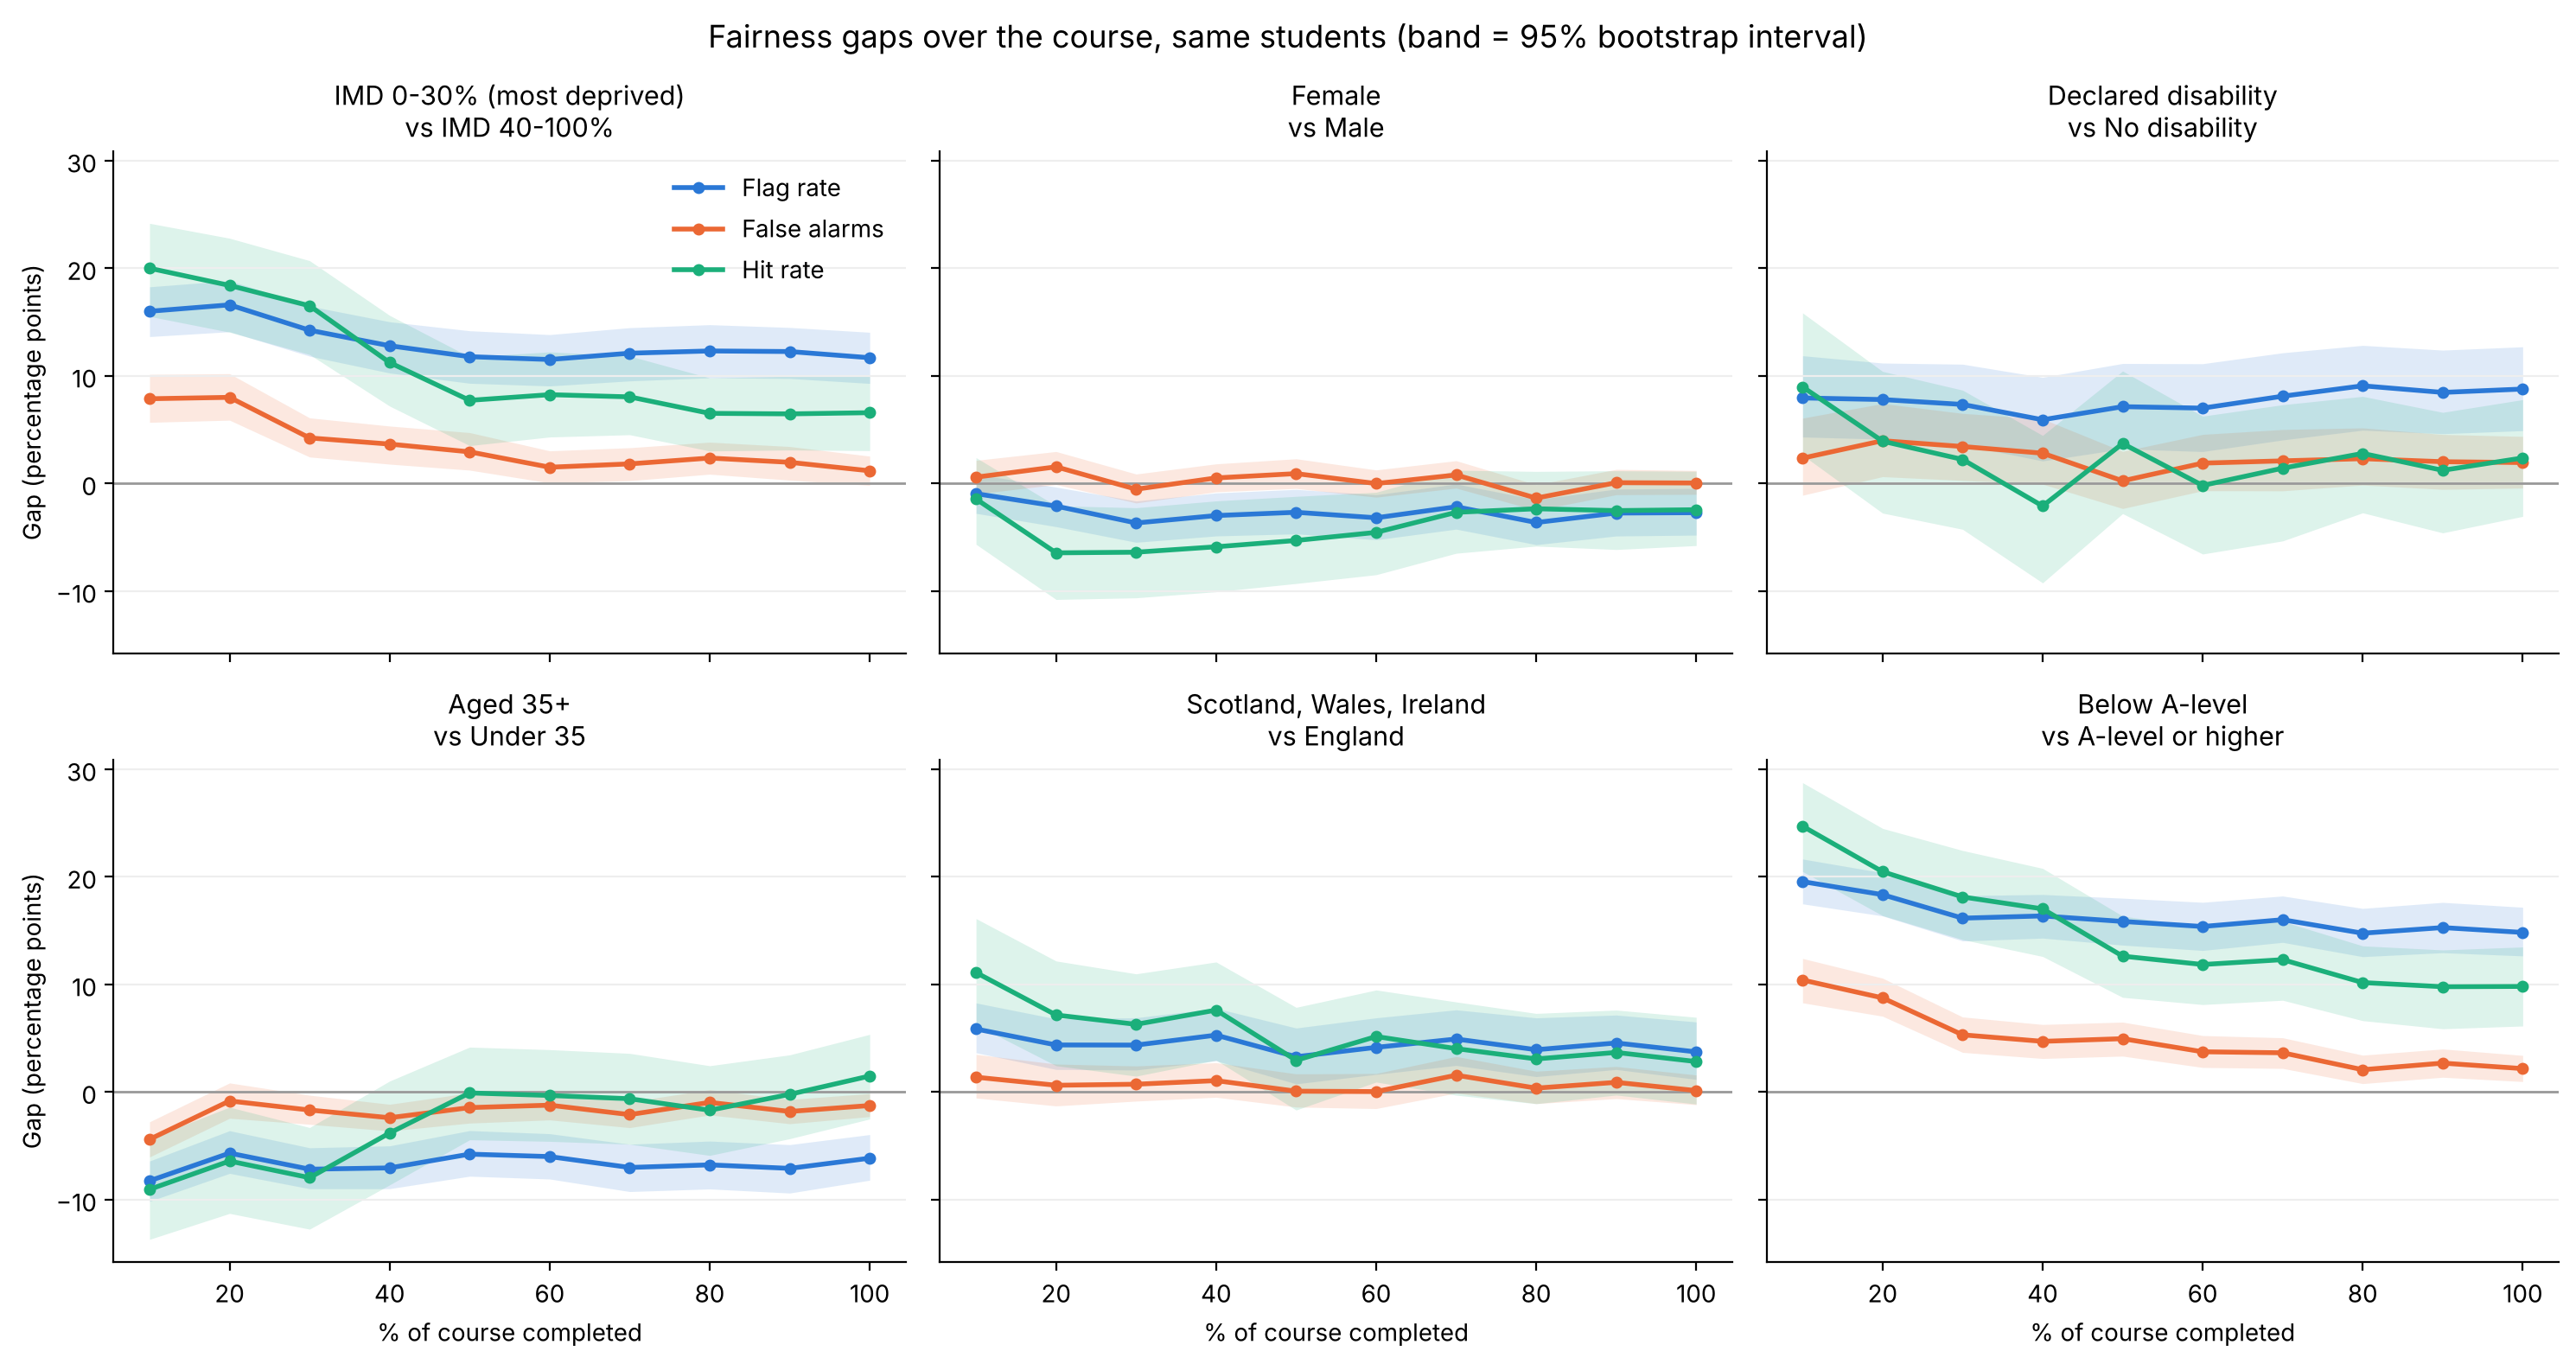

In [6]:
def plot_gaps(G, points, xlabel, title):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
    for ax, (a, (g1, g0)) in zip(axes.flat, ATTRS.items()):
        ax.axhline(0, color="#999", lw=1)
        for k in NAMES:
            d = G[(G.attr == a) & (G.metric == k)].sort_values("t")
            ax.fill_between(d.t, d.lo, d.hi, color=COLORS[k], alpha=0.15, lw=0)
            ax.plot(d.t, d.gap, color=COLORS[k], lw=2, marker="o", ms=4, label=NAMES[k])
        ax.set_title(f"{g1}\nvs {g0}", fontsize=11)
        ax.grid(axis="y", color="#eee"); ax.spines[["top", "right"]].set_visible(False)
    for ax in axes[1]: ax.set_xlabel(xlabel)
    for ax in axes[:, 0]: ax.set_ylabel("Gap (percentage points)")
    axes[0, 0].legend(frameon=False, fontsize=10)
    fig.suptitle(title, fontsize=13); fig.tight_layout(); plt.show()

plot_gaps(GAPS, PCTS, "% of course completed",
          "Fairness gaps over the course, same students (band = 95% bootstrap interval)")

**Check: calendar weeks instead of % of course.** If the shape is the same, the result does not depend on how time is measured.

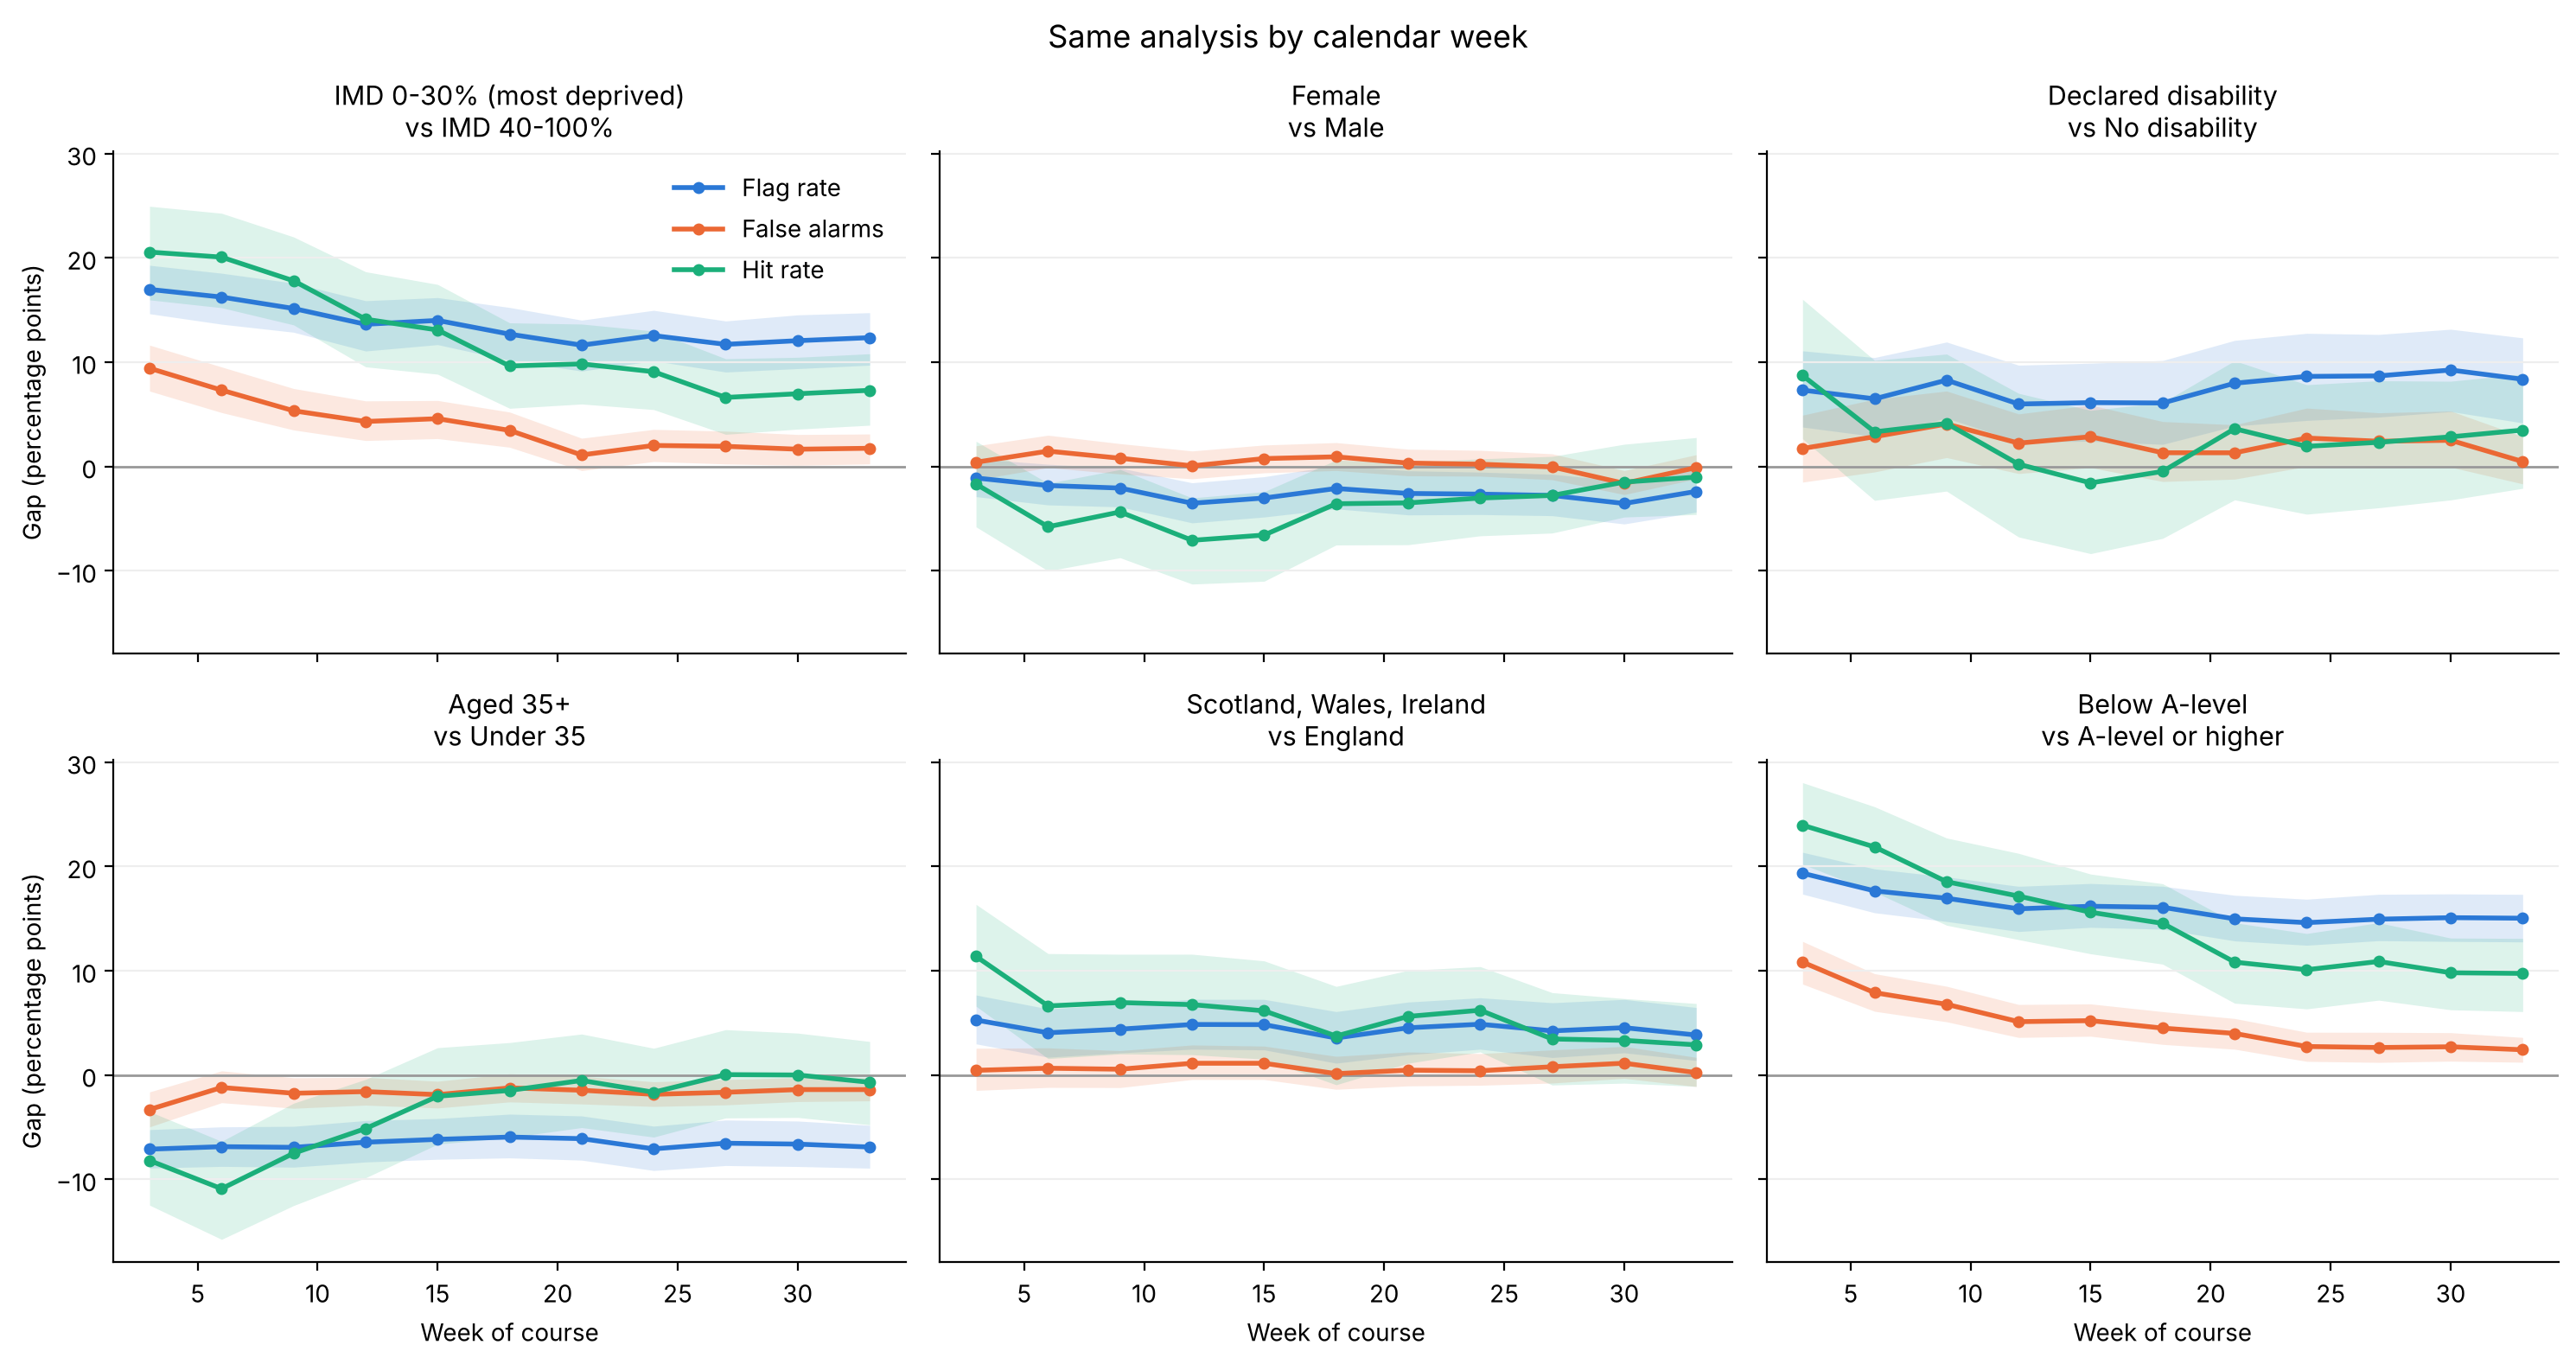

In [7]:
GAPS_W = gap_table(FITS_W, WEEKS)
plot_gaps(GAPS_W, WEEKS, "Week of course", "Same analysis by calendar week")

## 5. What is the model relying on?

**(a) Importance over time.** At each snapshot, shuffle a group of features in the test set and see how much the model's AUC drops. A bigger drop means the model relies on that group more.

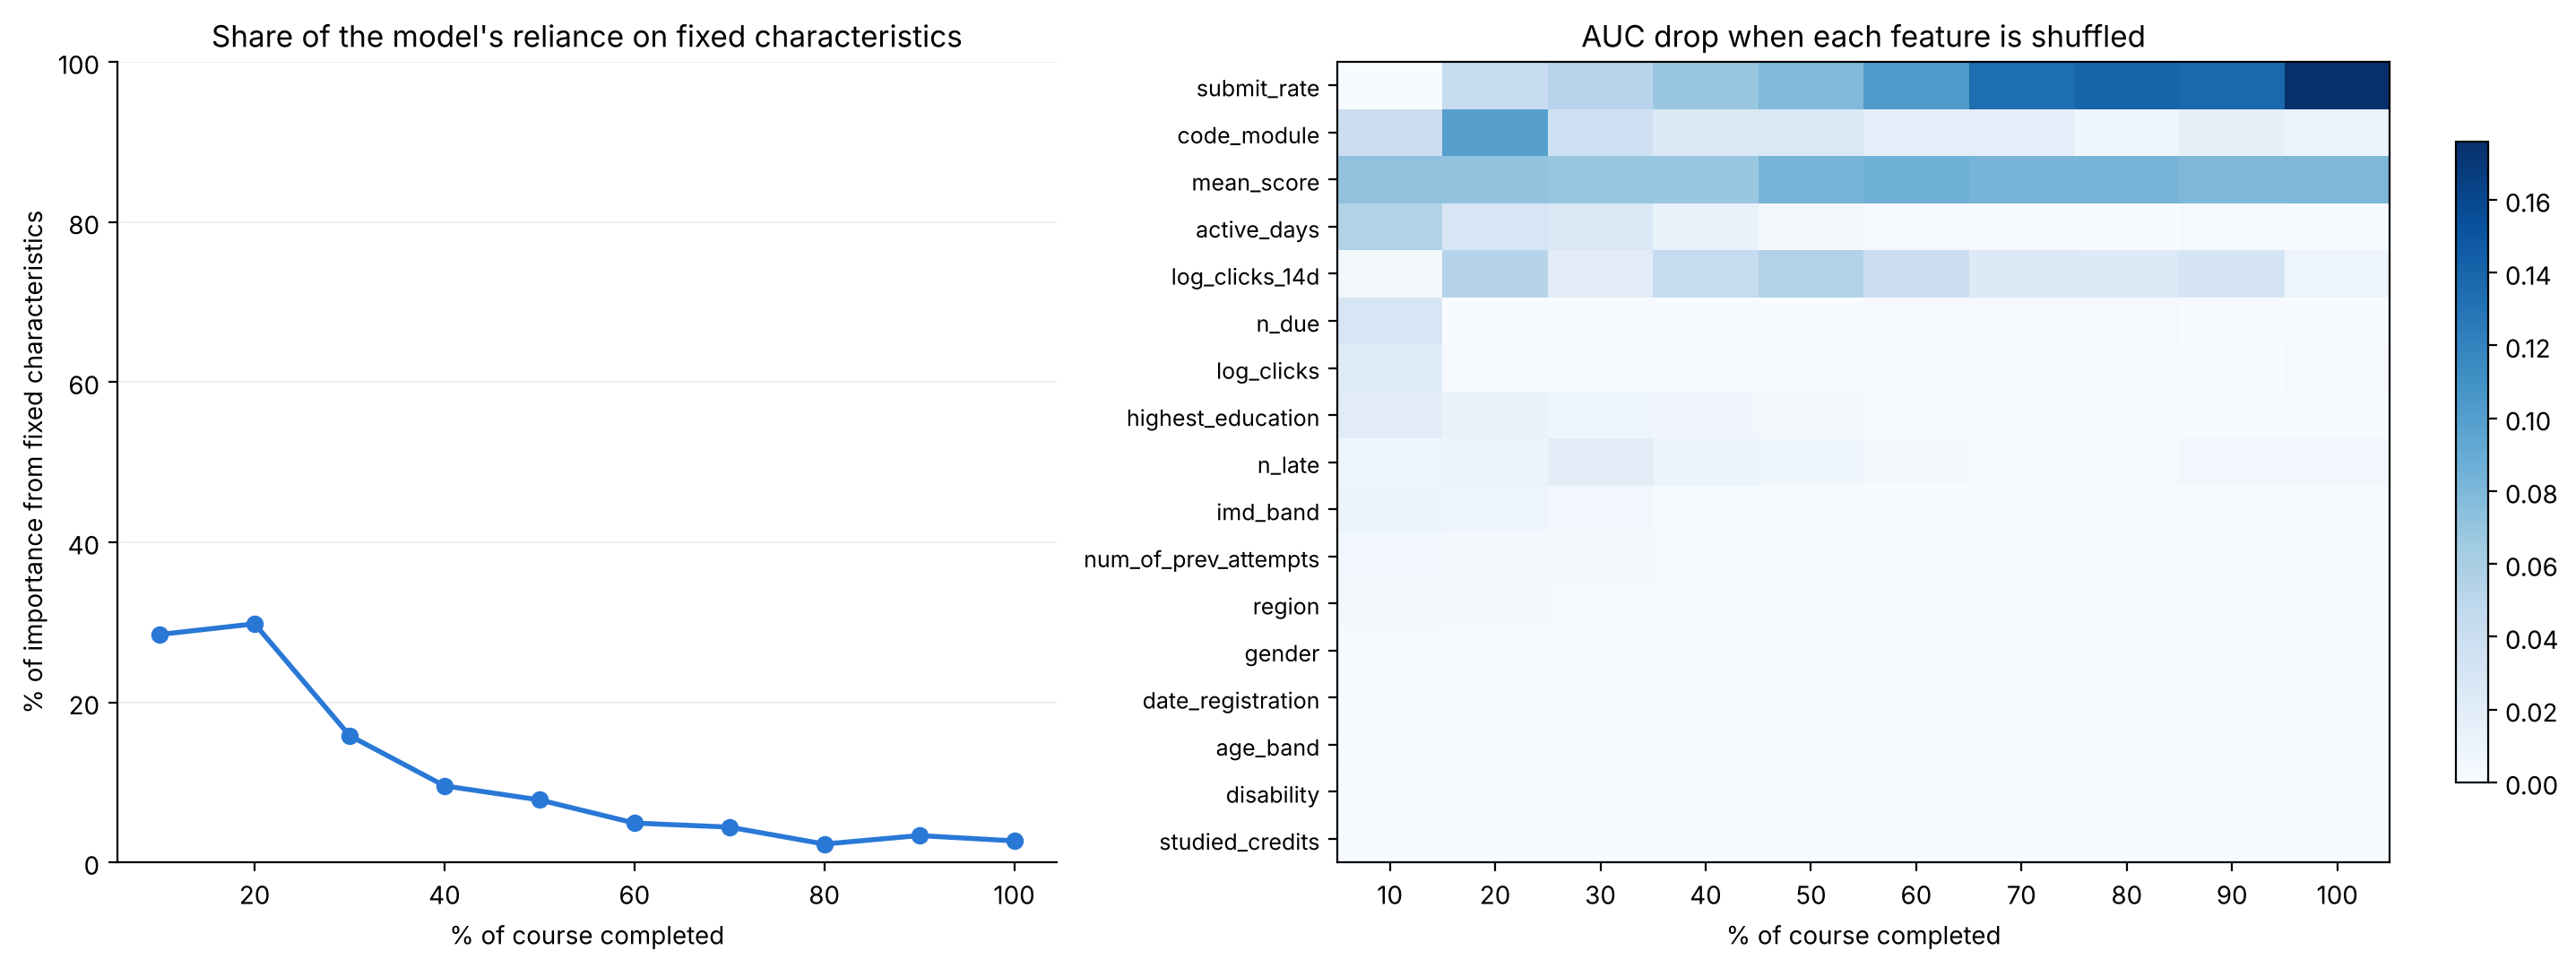

,fixed,behaviour,fixed share
10,0.085,0.214,0.285
20,0.122,0.287,0.298
30,0.059,0.315,0.158
40,0.037,0.349,0.096
50,0.032,0.382,0.078
60,0.021,0.403,0.049
70,0.019,0.418,0.044
80,0.010,0.429,0.023
90,0.015,0.442,0.034
100,0.012,0.439,0.027


In [8]:
COLS = {"fixed": FIXED_CAT + FIXED_NUM, "behaviour": BEHAV}

def group_importance(model, X, cols, reps=5):
    base = roc_auc_score(y_te, model.predict_proba(X)[:, 1])
    r = np.random.default_rng(SEED)
    drops = []
    for _ in range(reps):
        Xp = X.copy()
        idx = r.permutation(len(Xp))
        Xp[cols] = Xp[cols].values[idx]
        drops.append(base - roc_auc_score(y_te, model.predict_proba(Xp)[:, 1]))
    return np.mean(drops)

IMP = pd.DataFrame({p: {g: group_importance(FITS[p]["full"]["model"], SNAP[p].iloc[te], c) for g, c in COLS.items()} for p in PCTS}).T
IMP["fixed share"] = IMP.fixed / (IMP.fixed + IMP.behaviour)

FEATS = FIXED_CAT + FIXED_NUM + BEHAV
FEAT_IMP = pd.DataFrame({p: {f: group_importance(FITS[p]["full"]["model"], SNAP[p].iloc[te], [f], reps=3) for f in FEATS} for p in PCTS})

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})
a1.plot(IMP.index, IMP["fixed share"] * 100, color="#2a78d6", lw=2, marker="o")
a1.set_ylim(0, 100); a1.set_xlabel("% of course completed"); a1.set_ylabel("% of importance from fixed characteristics")
a1.set_title("Share of the model's reliance on fixed characteristics"); a1.grid(axis="y", color="#eee")
a1.spines[["top", "right"]].set_visible(False)
order = FEAT_IMP.max(axis=1).sort_values(ascending=False).index
im = a2.imshow(FEAT_IMP.loc[order].clip(lower=0), aspect="auto", cmap="Blues")
a2.set_yticks(range(len(order))); a2.set_yticklabels(order, fontsize=9)
a2.set_xticks(range(len(PCTS))); a2.set_xticklabels(PCTS); a2.set_xlabel("% of course completed")
a2.set_title("AUC drop when each feature is shuffled"); fig.colorbar(im, ax=a2, shrink=0.8)
fig.tight_layout(); plt.show()
IMP.round(3)

**(b) Does reliance on fixed characteristics track the fairness gap?** Each dot is one snapshot. With ten points this is descriptive, not proof; the comparison in (c) is the stronger test.

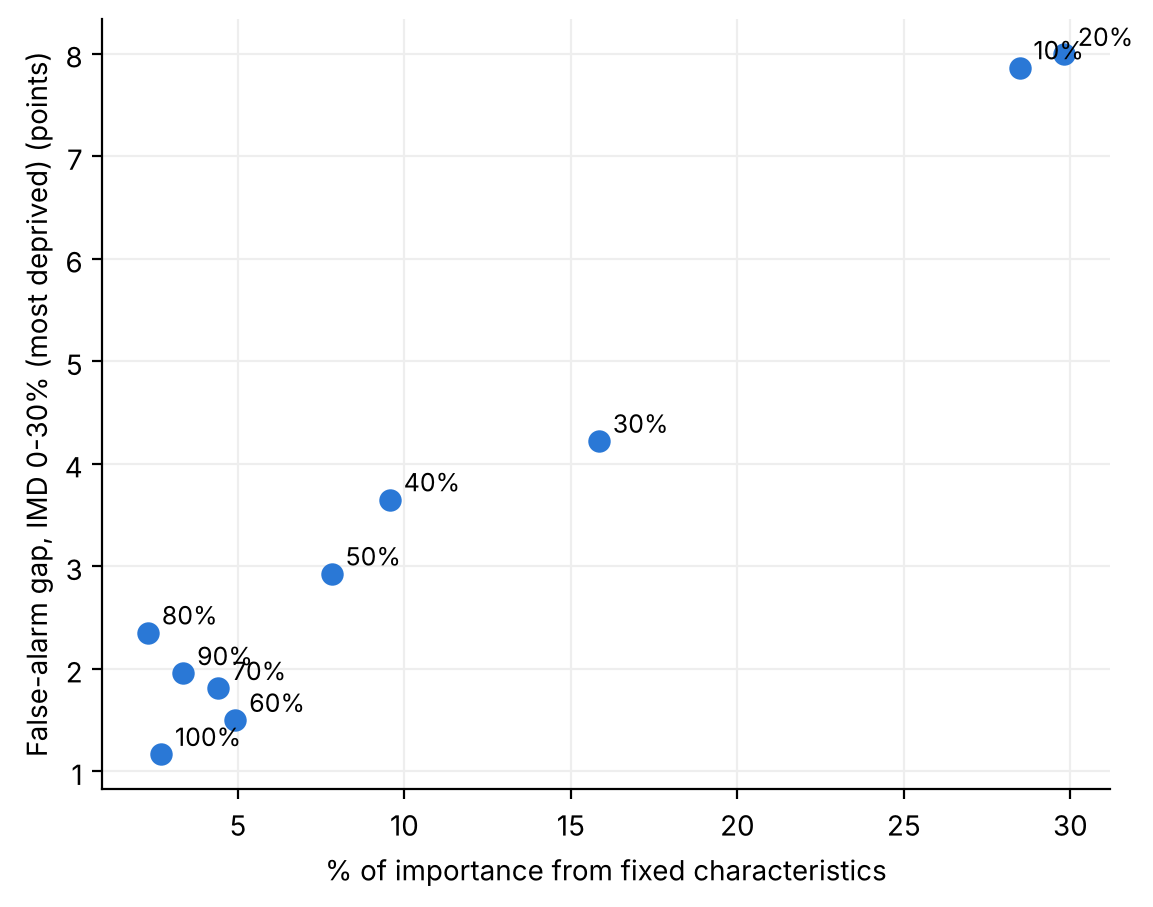

Spearman correlation, by attribute (fixed share vs false-alarm gap):
{'deprived': np.float64(0.83), 'female': np.float64(0.53), 'disabled': np.float64(0.59), 'age35': np.float64(-0.2), 'non_england': np.float64(0.25), 'low_edu': np.float64(0.98)}


In [9]:
fpr_focus = GAPS[(GAPS.attr == FOCUS) & (GAPS.metric == "fpr")].set_index("t").gap
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(IMP["fixed share"] * 100, fpr_focus, color="#2a78d6", s=50, zorder=3)
for p in PCTS: ax.annotate(f"{p}%", (IMP.loc[p, "fixed share"] * 100, fpr_focus[p]), xytext=(5, 3), textcoords="offset points", fontsize=9)
ax.set_xlabel("% of importance from fixed characteristics"); ax.set_ylabel(f"False-alarm gap, {ATTRS[FOCUS][0]} (points)")
ax.grid(color="#eee"); ax.spines[["top", "right"]].set_visible(False); plt.show()
print("Spearman correlation, by attribute (fixed share vs false-alarm gap):")
print({a: round(pd.Series(IMP["fixed share"].values).corr(pd.Series(GAPS[(GAPS.attr == a) & (GAPS.metric == "fpr")].sort_values("t").gap.values), method="spearman"), 2) for a in ATTRS})

**(c) Three models side by side:** fixed characteristics only, behaviour only, and both. If gaps shrink because behaviour takes over from demographics, the behaviour-only model should have small gaps throughout.

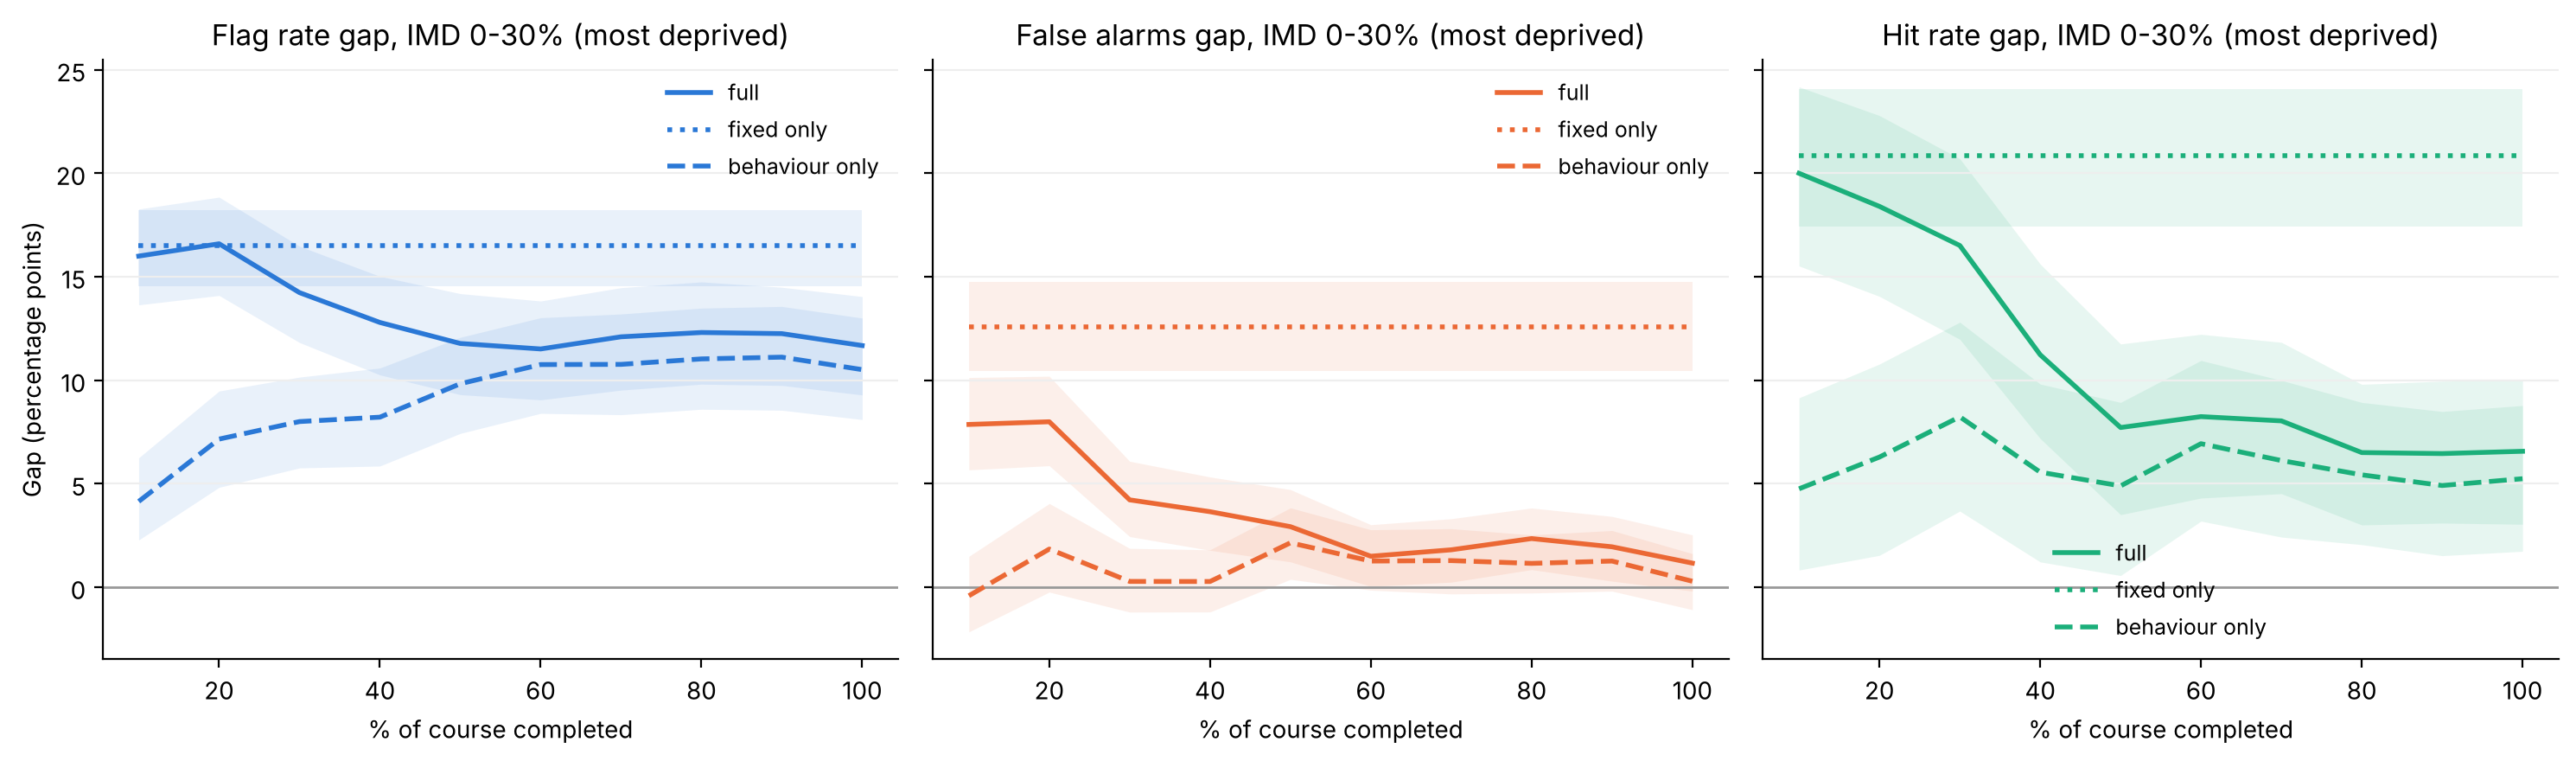

AUC by model:


,10,20,30,40,50,60,70,80,90,100
full,0.777,0.823,0.855,0.882,0.904,0.920,0.932,0.942,0.951,0.949
fixed only,0.651,0.651,0.651,0.651,0.651,0.651,0.651,0.651,0.651,0.651
behaviour only,0.730,0.760,0.829,0.868,0.889,0.912,0.926,0.939,0.946,0.944


In [10]:
rows = []
for name in FEATSETS:
    g = gap_table(FITS, PCTS, model=name); g["model"] = name; rows.append(g)
ABL = pd.concat(rows)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
styles = {"full": "-", "fixed only": ":", "behaviour only": "--"}
for ax, k in zip(axes, NAMES):
    ax.axhline(0, color="#999", lw=1)
    for name in FEATSETS:
        d = ABL[(ABL.attr == FOCUS) & (ABL.metric == k) & (ABL.model == name)].sort_values("t")
        ax.fill_between(d.t, d.lo, d.hi, color=COLORS[k], alpha=0.10, lw=0)
        ax.plot(d.t, d.gap, color=COLORS[k], ls=styles[name], lw=2, label=name)
    ax.set_title(f"{NAMES[k]} gap, {ATTRS[FOCUS][0]}"); ax.set_xlabel("% of course completed")
    ax.grid(axis="y", color="#eee"); ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("Gap (percentage points)"); fig.tight_layout(); plt.show()
print("AUC by model:")
pd.DataFrame({p: {n: roc_auc_score(y_te, FITS[p][n]["score"]) for n in FEATSETS} for p in PCTS}).round(3)

## 6. Does the data itself differ between groups?

Students who **passed**, compared by group: do the group of interest's passers look like failing students early on, and catch up later? If so, early false alarms reflect a real difference in the data, not only the model. Whole cohort, descriptive.

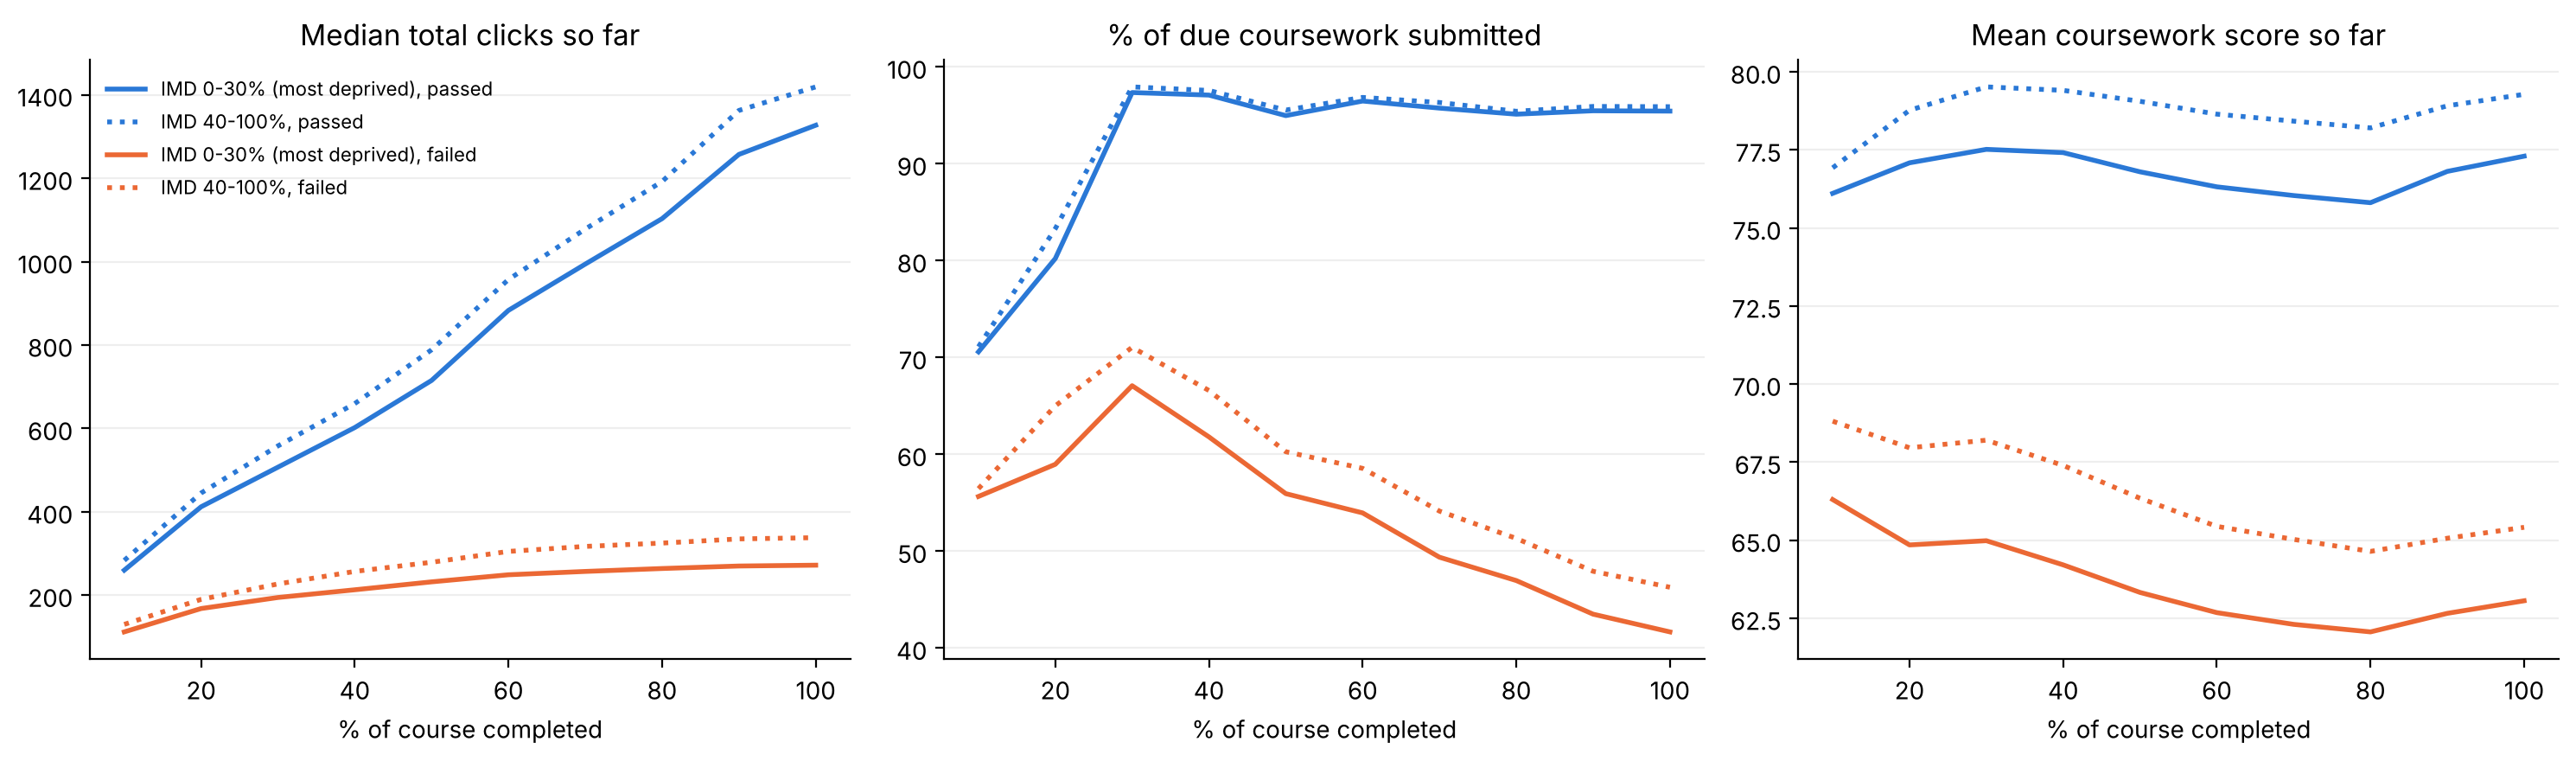

Passers' submission rate on a 0 (typical passer) to 100 (typical failer) scale:


,10,20,30,40,50,60,70,80,90,100
IMD 0-30% (most deprived),2.6,11.3,1.5,1.1,1.1,0.7,1.0,0.5,0.7,0.6
IMD 40-100%,-1.0,-4.3,-0.6,-0.4,-0.4,-0.3,-0.4,-0.2,-0.2,-0.2


In [11]:
def behaviour_by_group(a):
    rows = []
    for p in PCTS:
        X = SNAP[p]
        for (grp, yy), d in X[X[a].notna()].groupby([X[a], X.y]):
            rows.append(dict(t=p, group=ATTRS[a][0] if grp == 1 else ATTRS[a][1], outcome="Failed" if yy else "Passed",
                             clicks=d.clicks.median(), submit_rate=d.submit_rate.mean() * 100,
                             mean_score=d.mean_score[d.n_sub > 0].mean()))
    return pd.DataFrame(rows)

B = behaviour_by_group(FOCUS)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
lines = {(ATTRS[FOCUS][0], "Passed"): ("#2a78d6", "-"), (ATTRS[FOCUS][1], "Passed"): ("#2a78d6", ":"),
         (ATTRS[FOCUS][0], "Failed"): ("#eb6834", "-"), (ATTRS[FOCUS][1], "Failed"): ("#eb6834", ":")}
for ax, (col, lab) in zip(axes, [("clicks", "Median total clicks so far"), ("submit_rate", "% of due coursework submitted"),
                                 ("mean_score", "Mean coursework score so far")]):
    for (g, o), (c, ls) in lines.items():
        d = B[(B.group == g) & (B.outcome == o)]
        ax.plot(d.t, d[col], color=c, ls=ls, lw=2, label=f"{g}, {o.lower()}")
    ax.set_title(lab); ax.set_xlabel("% of course completed"); ax.grid(axis="y", color="#eee")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8); fig.tight_layout(); plt.show()

# Where do passers of each group sit between "typical passer" and "typical failer"? 0 = like passers, 100 = like failers
def failer_likeness(a, col):
    out = {}
    for p in PCTS:
        X = SNAP[p][SNAP[p][a].notna()]
        pas, fai = X[X.y == 0][col].mean(), X[X.y == 1][col].mean()
        out[p] = {ATTRS[a][0]: 100 * (pas - X[(X.y == 0) & (X[a] == 1)][col].mean()) / (pas - fai),
                  ATTRS[a][1]: 100 * (pas - X[(X.y == 0) & (X[a] == 0)][col].mean()) / (pas - fai)}
    return pd.DataFrame(out).round(1)
print("Passers' submission rate on a 0 (typical passer) to 100 (typical failer) scale:")
failer_likeness(FOCUS, "submit_rate")

## 7. What does it mean for students? (same test students tracked across the course)

**(a) How long false alarms last.** For each test student who went on to pass: at how many of the ten snapshots were they wrongly flagged?

In [12]:
PRED = np.column_stack([FITS[p]["full"]["pred"] for p in PCTS])   # test students x snapshots

def duration_table():
    rows = []
    for a, (g1, g0) in ATTRS.items():
        g = df[a].values[te]
        n_flag = PRED.sum(1)
        m1, m0 = (y_te == 0) & (g == 1), (y_te == 0) & (g == 0)
        boot = []
        for b in BOOT[:N_BOOT]:
            gb, yb, nb = g[b], y_te[b], n_flag[b]
            boot.append(nb[(yb == 0) & (gb == 1)].mean() - nb[(yb == 0) & (gb == 0)].mean())
        lo, hi = np.percentile(boot, [2.5, 97.5])
        rows.append({"attribute": f"{g1} vs {g0}", f"snapshots flagged, group": n_flag[m1].mean(),
                     "snapshots flagged, comparison": n_flag[m0].mean(), "difference": n_flag[m1].mean() - n_flag[m0].mean(),
                     "95% CI": f"[{lo:.2f}, {hi:.2f}]",
                     "flagged at 3+ snapshots, group": f"{(n_flag[m1] >= 3).mean():.1%}",
                     "flagged at 3+ snapshots, comparison": f"{(n_flag[m0] >= 3).mean():.1%}"})
    return pd.DataFrame(rows).set_index("attribute")

DUR = duration_table()
DUR.round(2)

,"snapshots flagged, group","snapshots flagged, comparison",difference,95% CI,"flagged at 3+ snapshots, group","flagged at 3+ snapshots, comparison"
attribute,,,,,,
IMD 0-30% (most deprived) vs IMD 40-100%,0.85,0.49,0.35,"[0.23, 0.47]",12.2%,7.3%
Female vs Male,0.59,0.56,0.02,"[-0.06, 0.11]",8.8%,8.1%
Declared disability vs No disability,0.78,0.55,0.23,"[0.04, 0.42]",11.6%,8.2%
Aged 35+ vs Under 35,0.45,0.63,-0.18,"[-0.27, -0.09]",6.7%,9.3%
"Scotland, Wales, Ireland vs England",0.63,0.56,0.07,"[-0.04, 0.19]",9.5%,8.1%
Below A-level vs A-level or higher,0.89,0.41,0.48,"[0.38, 0.59]",12.8%,6.2%


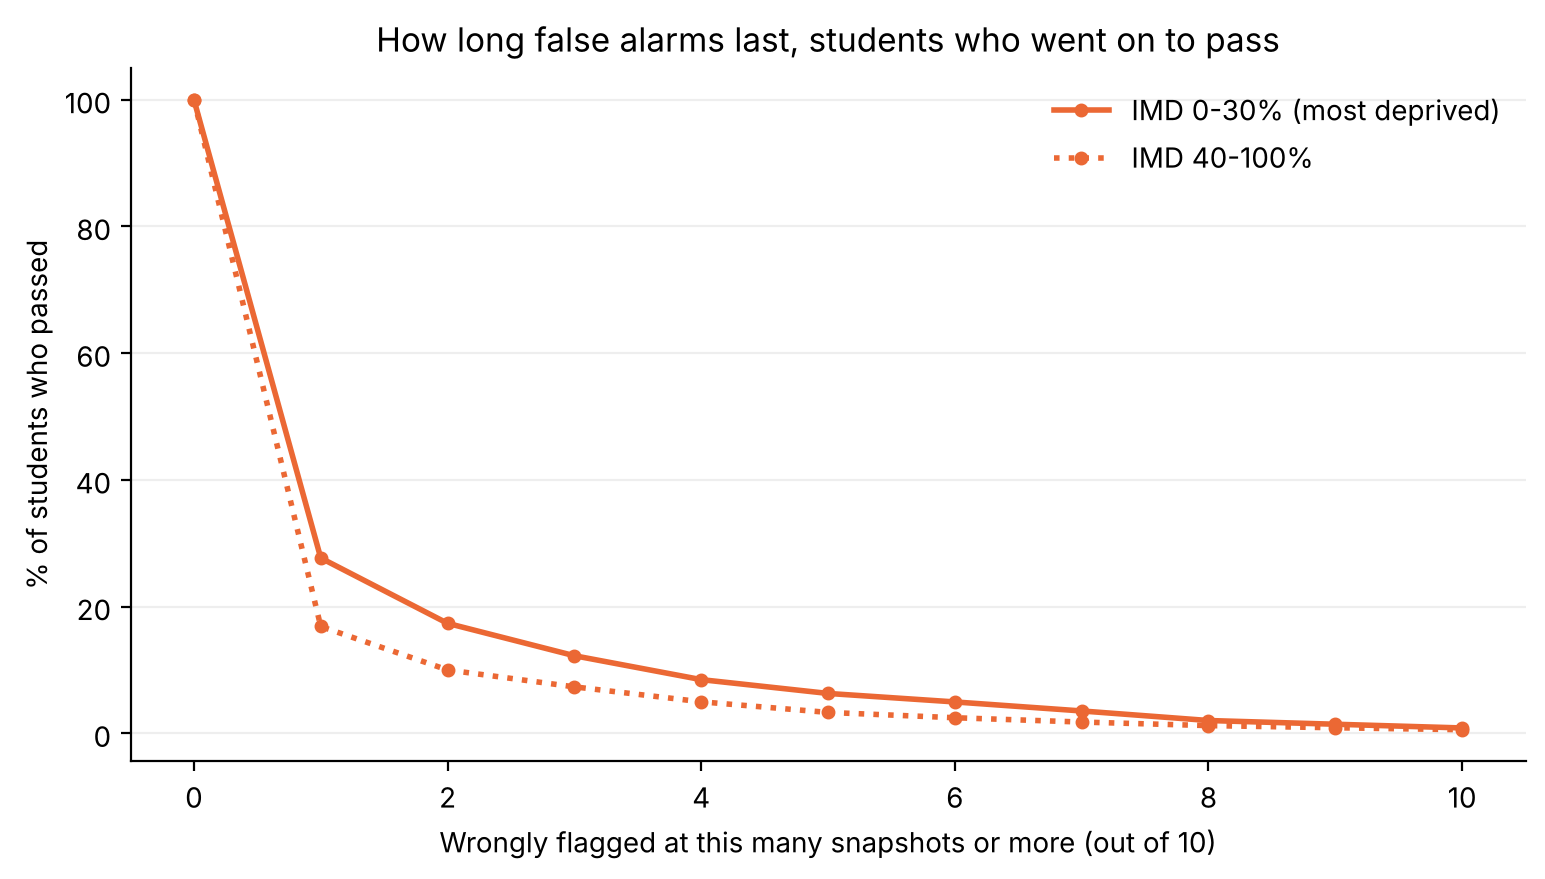

In [13]:
g = df[FOCUS].values[te]
fig, ax = plt.subplots(figsize=(9, 4.5))
ks = np.arange(0, 11)
for grp, ls, lab in [(1, "-", ATTRS[FOCUS][0]), (0, ":", ATTRS[FOCUS][1])]:
    n = PRED[(y_te == 0) & (g == grp)].sum(1)
    ax.plot(ks, [(n >= k).mean() * 100 for k in ks], color="#eb6834", ls=ls, lw=2, marker="o", ms=4, label=lab)
ax.set_xlabel("Wrongly flagged at this many snapshots or more (out of 10)"); ax.set_ylabel("% of students who passed")
ax.set_title("How long false alarms last, students who went on to pass"); ax.legend(frameon=False)
ax.grid(axis="y", color="#eee"); ax.spines[["top", "right"]].set_visible(False); plt.show()

**(b) How long until real risk is caught.** For each test student who failed: at which snapshot were they first flagged?

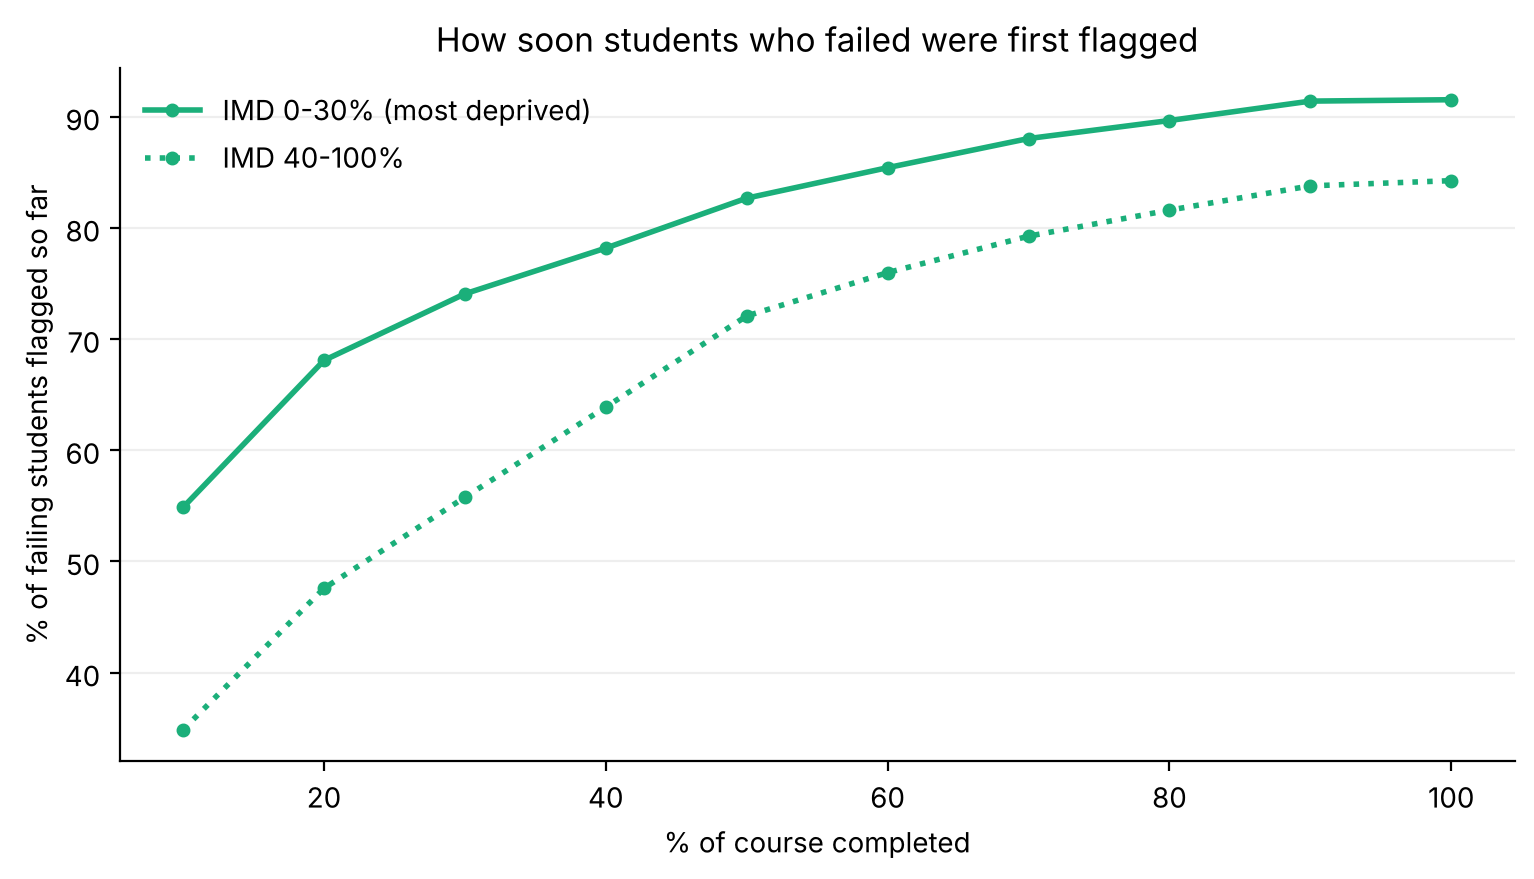

,"caught by 30%, group","caught by 30%, comparison","never caught, group","never caught, comparison"
IMD 0-30% (most deprived) vs IMD 40-100%,74.1%,55.8%,8.5%,15.8%
Female vs Male,60.0%,63.8%,13.7%,13.1%
Declared disability vs No disability,68.4%,61.4%,10.3%,13.7%
Aged 35+ vs Under 35,56.3%,64.2%,13.9%,13.2%
"Scotland, Wales, Ireland vs England",66.2%,60.8%,11.6%,13.9%
Below A-level vs A-level or higher,72.4%,52.4%,9.4%,17.1%


In [14]:
def first_flag(rows):
    """% of course at which each student was first flagged (NaN = never flagged)."""
    P = PRED[rows]
    first = np.array(PCTS, dtype=float)[P.argmax(1)]
    first[P.sum(1) == 0] = np.nan
    return first

fig, ax = plt.subplots(figsize=(9, 4.5))
summary = {}
for a, (g1, g0) in ATTRS.items():
    g = df[a].values[te]
    f1, f0 = first_flag((y_te == 1) & (g == 1)), first_flag((y_te == 1) & (g == 0))
    summary[f"{g1} vs {g0}"] = {"caught by 30%, group": f"{(f1 <= 30).mean():.1%}", "caught by 30%, comparison": f"{(f0 <= 30).mean():.1%}",
                                "never caught, group": f"{np.isnan(f1).mean():.1%}", "never caught, comparison": f"{np.isnan(f0).mean():.1%}"}
    if a == FOCUS:
        for f, ls, lab in [(f1, "-", g1), (f0, ":", g0)]:
            ax.plot(PCTS, [(f <= p).mean() * 100 for p in PCTS], color="#1baf7a", ls=ls, lw=2, marker="o", ms=4, label=lab)
ax.set_xlabel("% of course completed"); ax.set_ylabel("% of failing students flagged so far")
ax.set_title("How soon students who failed were first flagged"); ax.legend(frameon=False)
ax.grid(axis="y", color="#eee"); ax.spines[["top", "right"]].set_visible(False); plt.show()
pd.DataFrame(summary).T

## 8. Notes and limits
- One model (logistic regression) and one fixed split; the bands show uncertainty over which test students were drawn, not over the split. A check with several splits comes later.
- The cohort is students who finished the module. Students who withdrew are excluded, which suits an analytical study of the same students over time but not a deployed early-warning system.
- Coursework scores are counted when submitted; in practice marks arrive a little later.
- The 0.5 threshold is fixed throughout; flag rates depend on it.